# Alarme por câmera para o estoque (YOLO + cor do uniforme)
Detecta **pessoas** com YOLOv4-tiny e verifica se há **azul** (uniforme) no tronco. Se uma pessoa ficar vários frames sem azul, dispara alerta visual (borda/faixa vermelha) e sonoro.

Integrantes: Igor Zanatta Palliga, Guilherme Scherer, Gustavo Arthur Tedesco, Camile Favero Piassa

# 0. Instalar OpenCV 4.x (rode primeiro!)
O OpenCV 5 (padrão atual do Colab) removeu a leitura de modelos Darknet. Rode esta célula e, **se aparecer o botão "Reiniciar sessão", clique nele** (Ambiente de execução > Reiniciar sessão). Depois rode as células seguintes **sem** repetir esta.

In [ ]:
!pip install -q "opencv-python-headless<4.12" "numpy<2.3"
import cv2
print(cv2.__version__)   # deve mostrar 4.x
assert int(cv2.__version__.split(".")[0]) == 4, "Reinicie a sessão (Ambiente de execução > Reiniciar sessão) e rode de novo"

4.11.0


# 1. Download do modelo (cfg + pesos)
Usa o `cv2.dnn` para ler o modelo Darknet, então **não precisa compilar o Darknet**.

In [ ]:
!wget -q https://raw.githubusercontent.com/AlexeyAB/darknet/master/cfg/yolov4-tiny.cfg
!wget -q https://github.com/AlexeyAB/darknet/releases/download/yolov4/yolov4-tiny.weights
!ls -lh yolov4-tiny.*

-rw-r--r-- 1 root root 3.2K Nov 23 20:44 yolov4-tiny.cfg
-rw-r--r-- 1 root root 3.2K Nov 23 20:49 yolov4-tiny.cfg.1
-rw-r--r-- 1 root root  24M Dec  8  2021 yolov4-tiny.weights
-rw-r--r-- 1 root root  24M Dec  8  2021 yolov4-tiny.weights.1


# 2. Lógica do alarme
- `detecta_pessoas`: YOLO, só classe 0 (person)
- `tem_uniforme`: recorta o tronco, converte para HSV e mede a % de pixels azuis (3 faixas: escuro, médio, claro)
- `Monitor`: só dispara após `FRAMES_PARA_ALERTA` frames seguidos suspeitos, evitando falso alarme

Ajuste `AZUL_MIN_PCT` e `FAIXAS_AZUL` ao tom real do uniforme.

In [ ]:
import cv2, numpy as np

# ---------------- Configurações ----------------
CONF_MIN = 0.5          # confiança mínima para aceitar uma "pessoa"
NMS_MIN = 0.4           # supressão de caixas sobrepostas
AZUL_MIN_PCT = 0.12     # % mínima de pixels azuis no tronco para considerar uniforme
FRAMES_PARA_ALERTA = 25 # frames seguidos sem uniforme antes de disparar (evita falso alarme)

# Faixas de azul em HSV (OpenCV: H 0-179). Cobrem azul escuro, médio e claro.
FAIXAS_AZUL = [
    (np.array([100, 120, 40]),  np.array([130, 255, 255])),  # azul forte / escuro
    (np.array([95,  60,  60]),  np.array([135, 255, 255])),  # azul médio
    (np.array([90,  35, 120]),  np.array([135, 140, 255])),  # azul claro
]

def carrega_rede(cfg, pesos):
    net = cv2.dnn.readNetFromDarknet(cfg, pesos)
    modelo = cv2.dnn_DetectionModel(net)
    modelo.setInputParams(size=(416, 416), scale=1/255.0, swapRB=True)
    return modelo

def detecta_pessoas(modelo, frame):
    """Retorna lista de caixas (x, y, w, h) de pessoas (classe 0 do COCO)."""
    classes, confs, caixas = modelo.detect(frame, CONF_MIN, NMS_MIN)
    pessoas = []
    for c, caixa in zip(np.array(classes).flatten(), caixas):
        if int(c) == 0:
            pessoas.append(tuple(int(v) for v in caixa))
    return pessoas

def mascara_azul(hsv):
    m = np.zeros(hsv.shape[:2], np.uint8)
    for lo, hi in FAIXAS_AZUL:
        m |= cv2.inRange(hsv, lo, hi)
    return cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))

def tem_uniforme(frame, caixa):
    """Analisa só o tronco (miolo da parte superior da caixa) e mede o % de azul."""
    x, y, w, h = caixa
    x0, x1 = x + int(0.2 * w), x + int(0.8 * w)
    y0, y1 = y + int(0.15 * h), y + int(0.55 * h)
    H, W = frame.shape[:2]
    x0, x1, y0, y1 = max(x0, 0), min(x1, W), max(y0, 0), min(y1, H)
    roi = frame[y0:y1, x0:x1]
    if roi.size == 0:
        return False, 0.0
    pct = float(np.count_nonzero(mascara_azul(cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)))) / (roi.shape[0] * roi.shape[1])
    return pct >= AZUL_MIN_PCT, pct

class Monitor:
    """Processa frame a frame, mantém o contador de frames 'suspeitos' e decide o alerta."""
    def __init__(self, modelo):
        self.modelo = modelo
        self.seq_suspeito = 0
        self.alarme = False

    def processa(self, frame):
        pessoas = detecta_pessoas(self.modelo, frame)
        algum_suspeito = False
        for caixa in pessoas:
            ok, pct = tem_uniforme(frame, caixa)
            x, y, w, h = caixa
            cor = (0, 200, 0) if ok else (0, 0, 255)
            rotulo = f"Funcionario {pct:.0%}" if ok else f"SEM UNIFORME {pct:.0%}"
            cv2.rectangle(frame, (x, y), (x + w, y + h), cor, 3)
            cv2.putText(frame, rotulo, (x, max(y - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, cor, 2)
            algum_suspeito |= not ok
        self.seq_suspeito = self.seq_suspeito + 1 if algum_suspeito else 0
        self.alarme = self.seq_suspeito >= FRAMES_PARA_ALERTA
        if self.alarme:
            cv2.rectangle(frame, (0, 0), (frame.shape[1] - 1, frame.shape[0] - 1), (0, 0, 255), 12)
            cv2.rectangle(frame, (0, 0), (frame.shape[1], 50), (0, 0, 255), -1)
            cv2.putText(frame, "ALERTA: POSSIVEL ENTRADA NAO AUTORIZADA", (15, 35),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)
        return frame, len(pessoas), self.alarme


# 3. Teste em uma imagem

Pessoas: 1 | Alarme: False


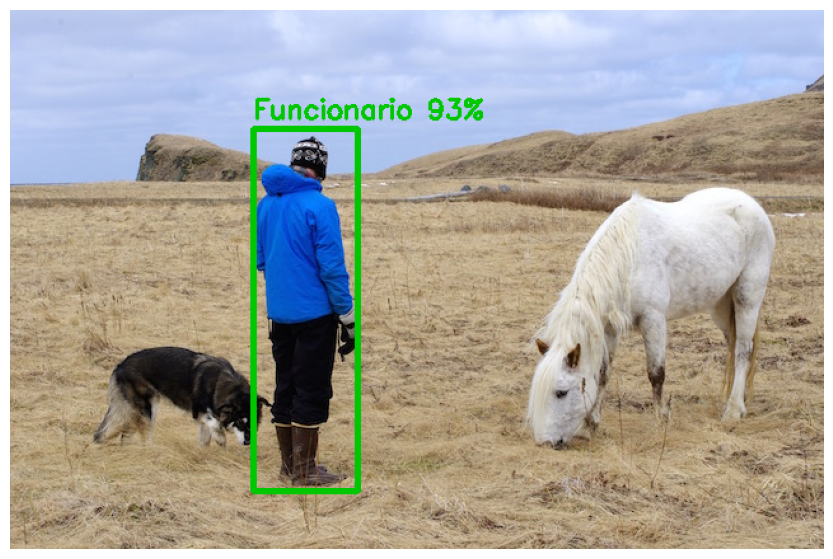

In [ ]:
!wget -q https://raw.githubusercontent.com/AlexeyAB/darknet/master/data/person.jpg
import matplotlib.pyplot as plt
modelo = carrega_rede('yolov4-tiny.cfg', 'yolov4-tiny.weights')
img = cv2.imread('person.jpg')
mon = Monitor(modelo)
for _ in range(FRAMES_PARA_ALERTA):      # repete o frame para simular tempo passando
    saida, n, alarme = mon.processa(img.copy())
plt.figure(figsize=(12, 7)); plt.axis('off')
plt.imshow(cv2.cvtColor(saida, cv2.COLOR_BGR2RGB))
print('Pessoas:', n, '| Alarme:', alarme)

Pessoas: 1 | Alarme: True


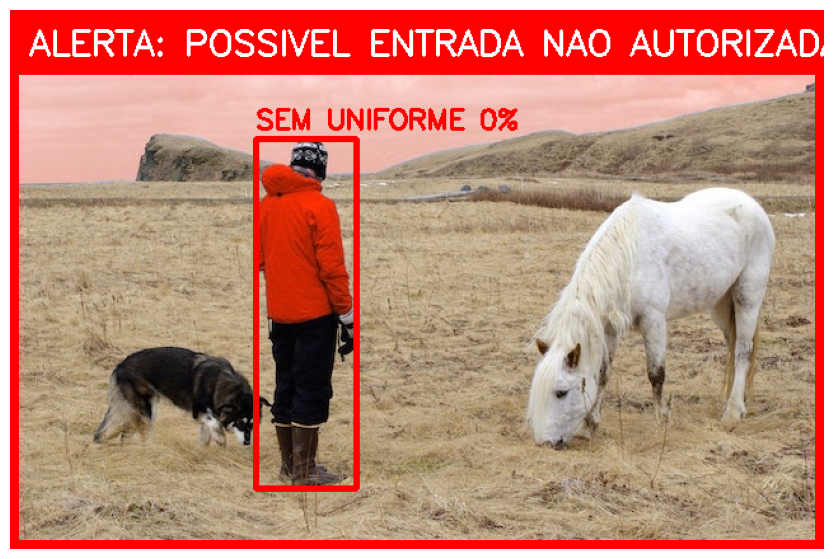

In [ ]:
!wget -q https://raw.githubusercontent.com/AlexeyAB/darknet/master/data/person.jpg
import matplotlib.pyplot as plt
modelo = carrega_rede('yolov4-tiny.cfg', 'yolov4-tiny.weights')
img = cv2.imread('pessoa2.jpg')
mon = Monitor(modelo)
for _ in range(FRAMES_PARA_ALERTA):      # repete o frame para simular tempo passando
    saida, n, alarme = mon.processa(img.copy())
plt.figure(figsize=(12, 7)); plt.axis('off')
plt.imshow(cv2.cvtColor(saida, cv2.COLOR_BGR2RGB))
print('Pessoas:', n, '| Alarme:', alarme)

# 4. Teste em vídeo
Envie um vídeo seu pelo painel de arquivos do Colab (ícone de pasta) e coloque o nome abaixo. Não precisa do Google Drive.

In [ ]:
ENTRADA = 'video_teste.mp4'         # <- nome do seu vídeo
SAIDA = 'resultado.mp4'

cap = cv2.VideoCapture(ENTRADA)
fps = cap.get(cv2.CAP_PROP_FPS) or 25
w, h = int(cap.get(3)), int(cap.get(4))
out = cv2.VideoWriter(SAIDA, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))
mon = Monitor(carrega_rede('yolov4-tiny.cfg', 'yolov4-tiny.weights'))
instantes_alarme = []
i = 0
while True:
    ok, frame = cap.read()
    if not ok: break
    frame, n, alarme = mon.processa(frame)
    if alarme: instantes_alarme.append(i / fps)
    out.write(frame); i += 1
cap.release(); out.release()
print(f'{i} frames processados. Alarme ativo em {len(instantes_alarme)} frames.')
if instantes_alarme:
    print(f'Primeiro alerta em {instantes_alarme[0]:.1f}s')

80 frames processados. Alarme ativo em 16 frames.
Primeiro alerta em 6.4s


# 5. Som do alerta dentro do vídeo
O Colab não toca som durante o processamento. Então geramos uma trilha de áudio com **bipes só nos momentos em que o alarme estava ativo** e juntamos ao vídeo. Ao dar play, a sirene toca quando aparece a faixa vermelha. (No computador, `alarme_local.py` toca em tempo real.)

In [ ]:
import numpy as np, wave

sr = 22050
dur = i / fps                                   # duração do vídeo (s)
t = np.arange(int(dur * sr)) / sr
ativo = np.zeros(len(t), bool)                  # 1 = alarme ativo nesse instante
for seg in instantes_alarme:
    ativo[int(seg * sr): int((seg + 1 / fps) * sr) + 1] = True
t0 = instantes_alarme[0] if instantes_alarme else 0                     # início do alarme
sirene = np.sin(2 * np.pi * 1800 * t) * (np.sin(2 * np.pi * 3 * (t - t0) + 0.5) > 0)  # bipe intermitente, já ligado em t0
audio = (sirene * ativo * 0.6 * 32767).astype(np.int16)
with wave.open('alarme.wav', 'wb') as f:
    f.setnchannels(1); f.setsampwidth(2); f.setframerate(sr); f.writeframes(audio.tobytes())

# junta vídeo (H.264, toca no navegador) + áudio do alarme
!ffmpeg -loglevel error -y -i resultado.mp4 -i alarme.wav -c:v libx264 -pix_fmt yuv420p -crf 28 -c:a aac -shortest resultado_web.mp4
print('Alarme ativo em', len(instantes_alarme), 'frames' if instantes_alarme else '(nenhum alerta)')

Alarme ativo em 16 frames


# 6. Ver o resultado aqui no notebook
Dê play e **ligue o volume**: a sirene toca junto com a faixa vermelha.

In [ ]:
from base64 import b64encode
from IPython.display import HTML
dados = open('resultado_web.mp4', 'rb').read()
print(f'Tamanho: {len(dados)/1e6:.1f} MB (vídeos longos podem ficar pesados; use o download abaixo)')
HTML(f'''<video width="720" controls>
  <source src="data:video/mp4;base64,{b64encode(dados).decode()}" type="video/mp4"></video>''')

Tamanho: 0.2 MB (vídeos longos podem ficar pesados; use o download abaixo)


# 7. Baixar o vídeo

In [ ]:
## from google.colab import files
## files.download('resultado_web.mp4')